# Hipótesis multivariada (cátedra)

A igual capacidad de huéspedes, un alojamiento se alquila más caro si garantiza mayor independencia: una cama para cada persona, mayor cantidad de baños por huésped y reserva automática.

**Preprocesamiento de las variables del análisis**

_Selección de variables_: se trabajó solo con `accommodates`, `beds`, `bathrooms`, `bathrooms_text`, `price_quote_price_per_night` (es la misma columna que `price`, pero sin símbolos, por lo que no requiere limpieza) e `instant_bookable`, sin preprocesar el resto del dataset.

_Reserva automática_: `instant_bookable` está completamente vacía (29.685 de 29.685 valores nulos), por lo que esta componente de la hipótesis no puede contrastarse y queda fuera del análisis.

_Resultado_: quedan 25.256 de 29.685 filas (se pierde el 14,9 %). Para evaluar si esto sesga el análisis se compararon las medianas de precio: 101.419 pesos en las filas conservadas contra 92.253 en las descartadas, una diferencia de alrededor del 9 %. Es un cambio leve, por lo que se continúa sin esas filas, y queda como limitación que las descartadas tienden a tener precios algo menores.

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

listings = pd.read_csv("listings (1).csv.gz")

cols = ["accommodates", "beds", "bathrooms", "bathrooms_text",
        "price_quote_price_per_night", "instant_bookable"]
df_hip = listings[cols].copy()

print(df_hip.shape)
print(df_hip.isna().sum())

(29685, 6)
accommodates                       0
beds                            2583
bathrooms                       3441
bathrooms_text                    26
price_quote_price_per_night     1792
instant_bookable               29685
dtype: int64


_Nulos_: `price_quote_price_per_night` tiene 6,0 % de nulos, `beds` 8,7 % y `bathrooms` 11,6 %. Se eliminaron las filas con nulos en cualquiera de estas variables, ya que son las que intervienen en el modelo y la base es lo bastante grande como para absorber esa pérdida. Los nulos de `bathrooms_text` (26) no se eliminan: más adelante esas filas se consideran con baño privado. Ninguna fila tenía precio o capacidad iguales a cero.


In [28]:
cols_modelo = ["accommodates", "beds", "bathrooms", "price_quote_price_per_night"]

dataset_without_null = df_hip.dropna(subset=cols_modelo)
dataset_without_null = dataset_without_null[
    (dataset_without_null["price_quote_price_per_night"] > 0) &
    (dataset_without_null["accommodates"] > 0)
].copy()

descartadas = df_hip.drop(dataset_without_null.index)

print(f"Filas antes: {len(df_hip)} | después: {len(dataset_without_null)} "
      f"| perdidas: {1 - len(dataset_without_null)/len(df_hip):.1%}")
print("Mediana de precio (conservadas):", dataset_without_null["price_quote_price_per_night"].median())
print("Mediana de precio (descartadas):", descartadas["price_quote_price_per_night"].median())

Filas antes: 29685 | después: 25256 | perdidas: 14.9%
Mediana de precio (conservadas): 101419.29000000001
Mediana de precio (descartadas): 92252.67


In [29]:
dataset_without_null["bath_per_huesped"] = (
    dataset_without_null["bathrooms"] / dataset_without_null["accommodates"])
dataset_without_null["cama_para_cada_uno"] = (
    dataset_without_null["beds"] >= dataset_without_null["accommodates"])

print(dataset_without_null["cama_para_cada_uno"].value_counts())
print(dataset_without_null["bath_per_huesped"].describe())
print(dataset_without_null["accommodates"].value_counts().sort_index())

cama_para_cada_uno
False    20502
True      4754
Name: count, dtype: int64
count    25256.000000
mean         0.496531
std          0.417782
min          0.062500
25%          0.333333
50%          0.500000
75%          0.500000
max         20.000000
Name: bath_per_huesped, dtype: float64
accommodates
1      1201
2     12094
3      4422
4      5177
5       958
6       799
7       143
8       194
9        45
10       68
11       18
12       32
13        5
14       14
15       15
16       71
Name: count, dtype: int64


_Baños compartidos_: se mantienen en el análisis. La hipótesis compara la independencia de un alojamiento, y compartir el baño con otras personas es una forma de menor independencia. Se identifican porque `bathrooms_text` contiene "shared" (las filas sin información en esa columna se consideran de baño privado) y se crea la variable binaria `banio_compartido`, que se incluye en el modelo como control. Esto es necesario porque estos alojamientos tienen un precio mediano muy inferior (49.296 contra 103.524) y, a la vez, más baños y más camas por huésped; sin controlarlos, sesgarían los coeficientes de baños y camas. Además, en un baño compartido `bathrooms` cuenta los baños del lugar y no los de uso propio, por lo que `bath_per_huesped` no es comparable entre ambos tipos.

_Exceso de baños_: se excluyen las filas con más baños que huéspedes (`bath_per_huesped` > 1; 197 filas, de las cuales 115 tienen baño compartido). Son casos excepcionales, posiblemente errores de carga, y un valor tan alto de la variable podría ejercer demasiada influencia en los resultados.

_Resultado_: quedan 23.253 filas, de las cuales 489 (2,1 %) tienen baño compartido, con 3.199 alojamientos con cama para cada uno y el resto sin ella.

In [30]:
# Capacidad entre 2 y 6 huéspedes
df_comp = dataset_without_null[dataset_without_null["accommodates"].between(2, 6)].copy()
print(len(df_comp), len(df_comp) / len(dataset_without_null))   # 23450, 0.928

# Baño compartido (variable de control) y exceso de baños (filtro)
df_comp["banio_compartido"] = (
    df_comp["bathrooms_text"].str.contains("shared", case=False, na=False).astype(int))
df_comp["exceso_banios"] = df_comp["bath_per_huesped"] > 1
print(df_comp["banio_compartido"].sum(), df_comp["exceso_banios"].sum(),
      ((df_comp["banio_compartido"] == 1) & df_comp["exceso_banios"]).sum())   # 604, 197, 115

df_comp2 = df_comp[~df_comp["exceso_banios"]].copy()
print(len(df_comp2), df_comp2["banio_compartido"].sum())   # 23253, 489
print(df_comp2["cama_para_cada_uno"].value_counts())

23450 0.9284922394678492
604 197 115
23253 489
cama_para_cada_uno
False    19883
True      3370
Name: count, dtype: int64


**Outliers de precio**

El precio tiene una cola derecha muy marcada: mediana 102.706, percentil 99 de 665.917 y máximo de 171.643.781. Como no se aplica transformación logarítmica, estos valores extremos dominan las medias y las varianzas.

Se usó la regla del IQR (Q3 + 1,5·IQR) calculada **dentro de cada capacidad** y no sobre toda la muestra, porque el precio crece con el número de huéspedes (mediana de ~90.000 con 2 huéspedes contra ~200.000 con 6) y un corte global eliminaría una proporción desmedida de alojamientos grandes (26 % de los de 5 huéspedes y 38 % de los de 6), sesgando la comparación a igual capacidad. No hay outliers por debajo, porque el límite inferior es negativo.

Se eliminaron 1.520 filas (6,5 %) y quedan 21.733. El corte afecta poco a las variables de la hipótesis: la proporción de alojamientos con cama para cada uno pasa de 14,5 % a 14,4 %, y se conservan 472 de las 489 filas con baño compartido.

IQR 1,5 por capacidad: 1520 eliminadas | 21733 quedan
IQR 3 por capacidad:   674 eliminadas | 22579 quedan
              out15  out3
accommodates             
2               772   352
3               273   126
4               356   157
5                65    24
6                54    15


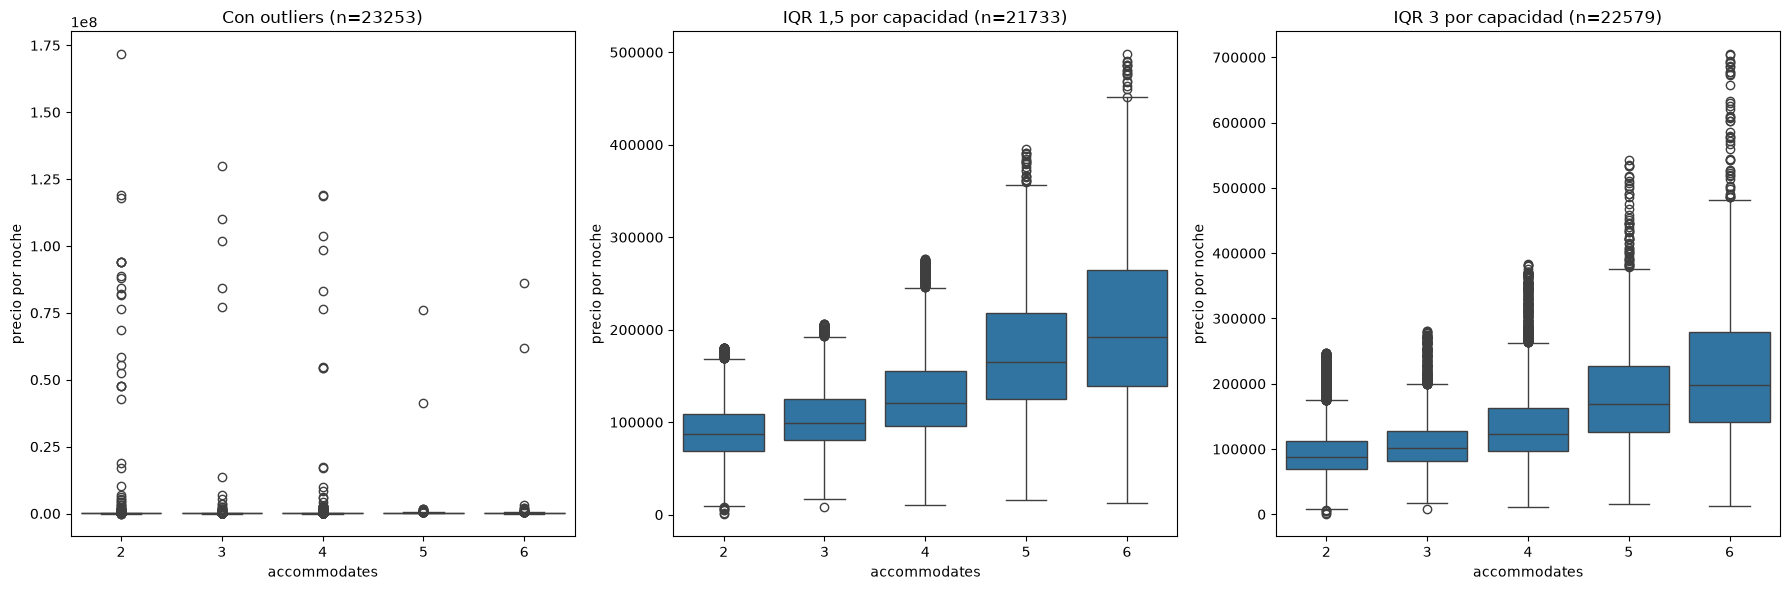

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

col = "price_quote_price_per_night"

def limite_iqr(s, k):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + k * (q3 - q1)

# Límites por capacidad (IQR 1,5 y IQR 3)
lim_15 = df_comp2.groupby("accommodates")[col].transform(lambda s: limite_iqr(s, 1.5))
lim_3 = df_comp2.groupby("accommodates")[col].transform(lambda s: limite_iqr(s, 3))

df_iqr15 = df_comp2[df_comp2[col] <= lim_15]
df_iqr3 = df_comp2[df_comp2[col] <= lim_3]

print("IQR 1,5 por capacidad:", len(df_comp2) - len(df_iqr15), "eliminadas |", len(df_iqr15), "quedan")
print("IQR 3 por capacidad:  ", len(df_comp2) - len(df_iqr3), "eliminadas |", len(df_iqr3), "quedan")

# Eliminadas por capacidad con cada criterio
resumen = (df_comp2.assign(out15=df_comp2[col] > lim_15, out3=df_comp2[col] > lim_3)
           .groupby("accommodates")[["out15", "out3"]].sum())
print(resumen)

# Boxplots
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, data, titulo in [
    (ax[0], df_comp2, f"Con outliers (n={len(df_comp2)})"),
    (ax[1], df_iqr15, f"IQR 1,5 por capacidad (n={len(df_iqr15)})"),
    (ax[2], df_iqr3, f"IQR 3 por capacidad (n={len(df_iqr3)})"),
]:
    sns.boxplot(data=data, x="accommodates", y=col, ax=a)
    a.set_title(titulo)
    a.set_xlabel("accommodates")
    a.set_ylabel("precio por noche")

plt.tight_layout()
plt.show()

In [32]:
col = "price_quote_price_per_night"

def limite_iqr(s, k=3):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + k * (q3 - q1)

limites = df_comp2.groupby("accommodates")[col].transform(limite_iqr)
es_outlier = df_comp2[col] > limites
print(es_outlier.sum(), (~es_outlier).sum())   # 674, 22579

df_final = df_comp2[~es_outlier].copy()
print(len(df_final), df_final["banio_compartido"].sum())      # 22579, 478
print(df_final["cama_para_cada_uno"].mean())                  # ~0.145

674 22579
22579 478
0.14504628194339875


**Outliers de precio**

El precio tiene una cola derecha muy marcada: mediana 102.706, percentil 99 de 665.917 y máximo de 171.643.781.

Se usó la regla del IQR calculada **dentro de cada capacidad** y no sobre toda la muestra, porque el precio crece con el número de huéspedes (mediana de ~90.000 con 2 huéspedes contra ~200.000 con 6) y un corte global eliminaría una proporción desmedida de alojamientos grandes (con IQR 1,5 global, el 26 % de los de 5 huéspedes y el 38 % de los de 6), sesgando la comparación a igual capacidad.

Se eligió el umbral Q3 + 3·IQR en lugar de 1,5·IQR para eliminar solo los valores extremos y conservar precios altos que pueden ser legítimos, sobre todo en alojamientos de mayor capacidad: con 1,5 se habrían eliminado 1.520 filas (6,5 %) y con 3 se eliminan 674 (2,9 %). No hay outliers por debajo, porque el límite inferior es negativo.

Quedan 22.579 filas. El corte afecta poco a las variables de la hipótesis: la proporción de alojamientos con cama para cada uno se mantiene en 14,5 % y se conservan 478 de las 489 filas con baño compartido.

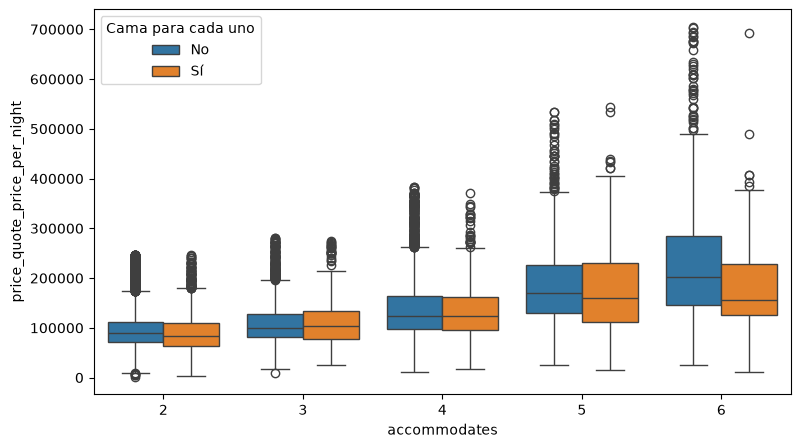

cama_txt            No        Sí
accommodates                    
2              89031.0   84519.0
3             100652.0  103581.0
4             123254.0  122982.0
5             170544.0  159486.0
6             202645.0  155255.0


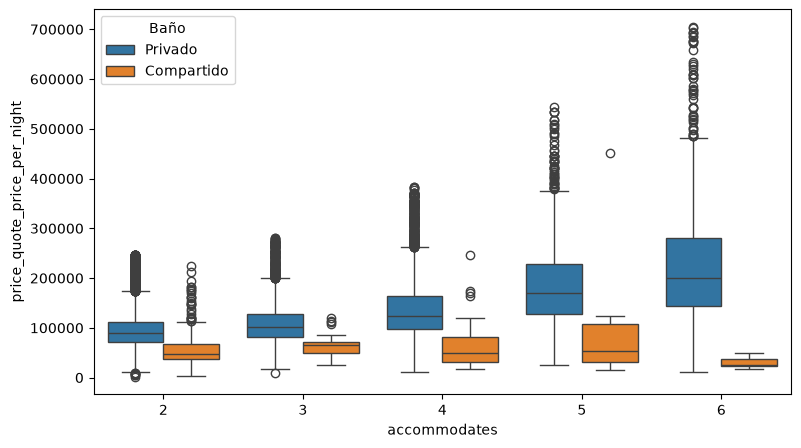

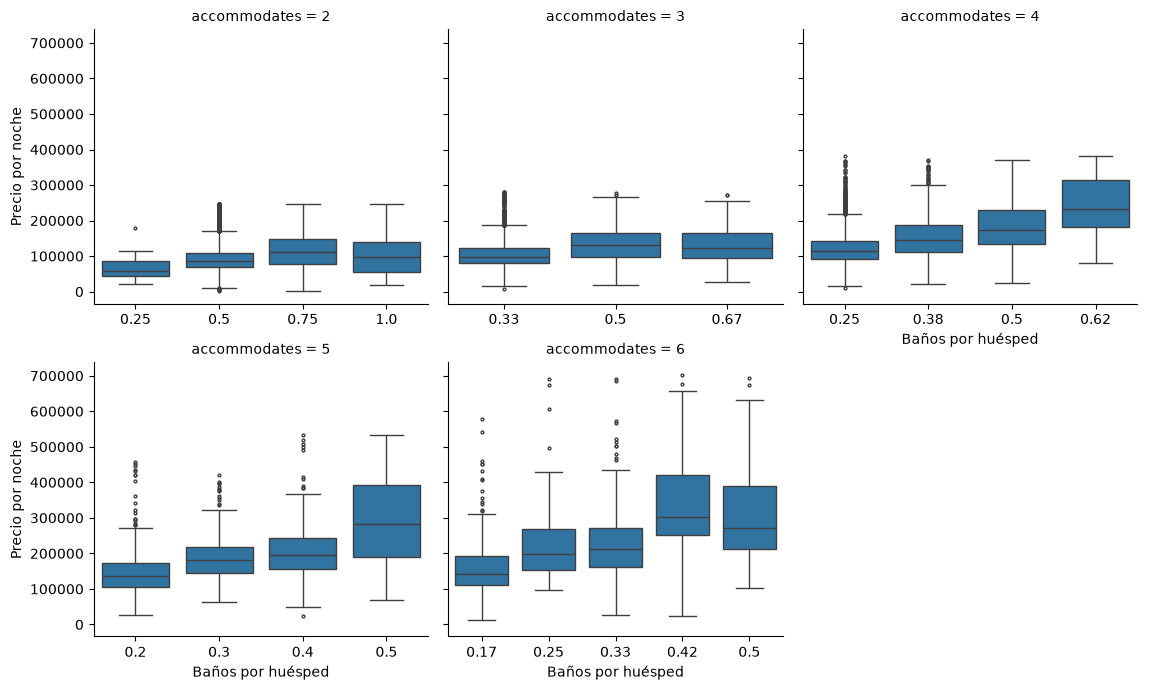

Global: -0.201
2 0.101
3 0.216
4 0.395
5 0.435
6 0.483


In [33]:
col = "price_quote_price_per_night"
df_final["cama_txt"] = df_final["cama_para_cada_uno"].map({False: "No", True: "Sí"})
df_final["compartido_txt"] = df_final["banio_compartido"].map({0: "Privado", 1: "Compartido"})

# 1. Precio por capacidad y cama para cada uno
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_final, x="accommodates", y=col, hue="cama_txt", hue_order=["No", "Sí"])
plt.legend(title="Cama para cada uno")
plt.show()
print(df_final.groupby(["accommodates", "cama_txt"])[col].median().unstack().round(0))

# 2. Precio por capacidad y tipo de baño
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_final, x="accommodates", y=col, hue="compartido_txt",
            hue_order=["Privado", "Compartido"])
plt.legend(title="Baño")
plt.show()

col = "price_quote_price_per_night"
df_final["bath_cat"] = df_final["bath_per_huesped"].round(2)

# Se descartan los valores de baños por huésped con menos de 30 filas dentro de cada capacidad
tam = df_final.groupby(["accommodates", "bath_cat"])["bath_cat"].transform("size")
df_box = df_final[tam >= 30]

g = sns.catplot(data=df_box, x="bath_cat", y=col,
                col="accommodates", col_wrap=3, kind="box",
                sharex=False, height=3.5, aspect=1.1, fliersize=2)
g.set_axis_labels("Baños por huésped", "Precio por noche")
g.set_titles("accommodates = {col_name}")
plt.show()

# Correlación de Spearman: global y por capacidad
print("Global:", round(df_final["bath_per_huesped"].corr(df_final[col], method="spearman"), 3))
for a, g in df_final.groupby("accommodates"):
    print(a, round(g["bath_per_huesped"].corr(g[col], method="spearman"), 3))

**Hipótesis y modelo**

La hipótesis plantea que, a igual capacidad, un alojamiento es más caro si garantiza mayor independencia. Se evalúan dos componentes (la reserva automática no puede evaluarse porque `instant_bookable` está vacía):

- Camas: H0: β(cama para cada uno) = 0 vs H1: β > 0.
- Baños: H0: β(baños por huésped) = 0 vs H1: β > 0.

Se ajusta un OLS sobre el precio por noche, sin transformaciones, con la capacidad como variable categórica (referencia: 2 huéspedes), `cama_para_cada_uno`, `bath_per_huesped` y la variable de control `banio_compartido`. El modelo explica el 34,2 % de la variación del precio (R² = 0,342) con 22.579 filas.

- _Baños por huésped_: el coeficiente es positivo y muy significativo (≈ +156.768 por cada baño por huésped adicional; por ejemplo, +39.000 al pasar de 1 a 2 baños con 4 huéspedes), lo que es consistente con la hipótesis.
- _Cama para cada uno_: el coeficiente es pequeño y negativo (≈ −2.411; p bilateral = 0,011), el signo contrario al esperado, por lo que el test unilateral no rechaza H0 (p ≈ 0,99).
- _Baño compartido_: reduce el precio en ≈ 64.153 a igual capacidad, camas y baños por huésped, lo que confirma la necesidad de controlarlo.

Estos p-valores asumen varianza constante y errores normales; ambos supuestos se verifican a continuación.

ValueError: unrecognized data structures: <class 'str'> / <class 'NoneType'>

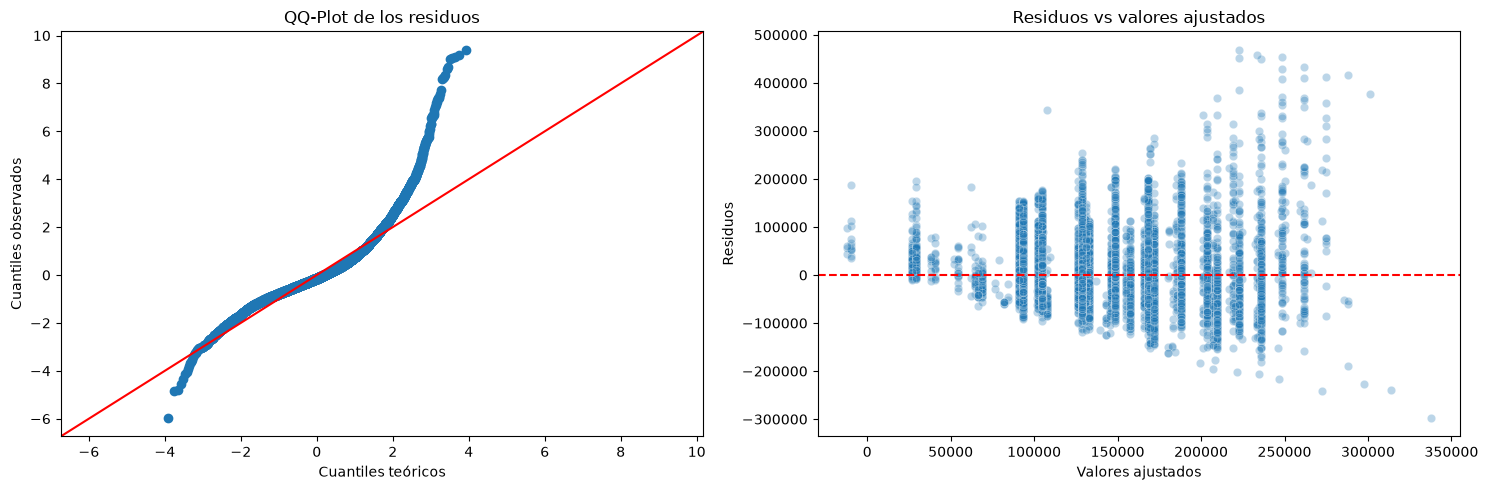

SHAPIRO-WILK - NORMALIDAD
Estadístico W: 0.88946
p-valor: 0.000000

BREUSCH-PAGAN - HOMOCEDASTICIDAD
Estadístico LM: 2997.49164
p-valor LM: 0.000000
Estadístico F: 493.58801
p-valor F: 0.000000


In [50]:
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
import matplotlib.pyplot as plt
import seaborn as sns

# Residuos y valores ajustados del modelo
residuos = modelo.resid
ajustados = modelo.fittedvalues

# Crear dos gráficos lado a lado
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# 1. QQ-Plot: Normalidad
sm.qqplot(residuos, line="45", fit=True, ax=ax[0])
ax[0].set_title("QQ-Plot de los residuos")
ax[0].set_xlabel("Cuantiles teóricos")
ax[0].set_ylabel("Cuantiles observados")

# 2. Scatterplot: Homocedasticidad
sns.scatterplot(x=ajustados, y=residuos, alpha=0.3, ax=ax[1])
ax[1].axhline(y=0, color="red", linestyle="--")
ax[1].set_title("Residuos vs valores ajustados")
ax[1].set_xlabel("Valores ajustados")
ax[1].set_ylabel("Residuos")

plt.tight_layout()
plt.show()


# -------------------------------
# PRUEBAS ESTADÍSTICAS
# -------------------------------

# Shapiro-Wilk
# Se toma una muestra aleatoria de 5000 residuos
muestra = residuos.sample(n=5000, random_state=42)

shapiro_stat, shapiro_p = stats.shapiro(muestra)

print("SHAPIRO-WILK - NORMALIDAD")
print(f"Estadístico W: {shapiro_stat:.5f}")
print(f"p-valor: {shapiro_p:.6f}")

# Breusch-Pagan
bp = het_breuschpagan(residuos, modelo.model.exog)

bp_stat, bp_p, bp_f, bp_f_p = bp

print("\nBREUSCH-PAGAN - HOMOCEDASTICIDAD")
print(f"Estadístico LM: {bp_stat:.5f}")
print(f"p-valor LM: {bp_p:.6f}")
print(f"Estadístico F: {bp_f:.5f}")
print(f"p-valor F: {bp_f_p:.6f}")



En el QQ-plot se ve como claramente la distribucion no es normal y para confirmarlo el test Shapiro-Wilks donde el p-valor es igual a cero. Si evaluamos la existencia de la homocedasticidad el grafico de puntos (scatterplot), ya nos dice que claramente estamos ante un conjunto con una distribucion con heterocedasticidad por que tiene forma de embudo que se abre y para complementar el test de Breusch-Pagan lo confirma dado que p-valor es igual a cero.

Como los supuesto no se cumplen deberiamos de usar Kruskal-Wallis pero antes de eso hay que retocar un poco las variables por que Kruskal evalua si existe diferencias significativas en las medianas de 3 o mas grupos, entonces primero tenemos que armas esos grupos.

Hay que crear nuevas variable que donde se combinen `cama_para_cada_uno` y `bath_per_huesped`. Como `bath_per_huesped` es continua lo que podemos hacer es discretizarla usando la mediana de la columna como punto de corte y diferenciar entre "bajo ratio de baños" vs "alto ratio de baños"

Los grupos nos quedarian tal que:
+ Sin cama para todos + Bajo ratio de baños
+ Sin cama para todos + Alto ratio de baños
+ Cama para todos + bajo ratio de baños
+ Cama para todos + alto ratio de baños

El hecho de categorizar la variable continua nos permite validar la hipotesis de forma conjunta mediante grupos claros a costa de perder un poco de variabilidad y precision en los datos.

Tambien para no entorpecer el resultado del test deberiamos de eliminar todos los baños compartidos ya que un baño compartido podria caer accidentalmente en los grupos de alta independencia (grupo 3 y 4), y como vimos el hecho de que en el alojamiento haya baños compartidos abarata el precio apoyando el hecho que busca validar la hipotesis que es a mayor independencia mayor es el precio.

In [37]:
# Conservamos únicamente las filas donde el baño NO es compartido
df_final= df_final[df_final['banio_compartido'] == False]

In [43]:
import numpy as np
from scipy import stats

# 1. Calculamos la mediana del ratio de baños (asegúrate de correr esto SOBRE el df ya filtrado)
mediana_banios = df_final['bath_per_huesped'].median()

# 2. Definimos las condiciones lógicas para nuestros 4 grupos
condiciones = [
    (df_final['cama_para_cada_uno'] == False) & (df_final['bath_per_huesped'] <= mediana_banios), # Grupo 1
    (df_final['cama_para_cada_uno'] == False) & (df_final['bath_per_huesped'] > mediana_banios),  # Grupo 2
    (df_final['cama_para_cada_uno'] == True)  & (df_final['bath_per_huesped'] <= mediana_banios), # Grupo 3
    (df_final['cama_para_cada_uno'] == True)  & (df_final['bath_per_huesped'] > mediana_banios)   # Grupo 4
]

# 3. Definimos las etiquetas o nombres para cada grupo
etiquetas = [
    '1 - Menor Independencia', 
    '2 - Intermedio Bajo', 
    '3 - Intermedio Alto', 
    '4 - Mayor Independencia'
]

# 4. Creamos la nueva columna en el DataFrame
# Agregamos default='Sin clasificar' para que todos los datos sean de tipo texto
df_final['nivel_independencia'] = np.select(condiciones, etiquetas, default='Sin clasificar')

# Vemos cuántas filas quedaron en cada grupo para asegurar que no haya grupos vacíos
print("Distribución de los grupos:")
print(df_final['nivel_independencia'].value_counts())

Distribución de los grupos:
nivel_independencia
1 - Menor Independencia    17994
3 - Intermedio Alto         2907
2 - Intermedio Bajo         1002
4 - Mayor Independencia      198
Name: count, dtype: int64


In [44]:
# Separamos los precios de cada grupo
precio_g1 = df_final[df_final['nivel_independencia'] == '1 - Menor Independencia']['price_quote_price_per_night']
precio_g2 = df_final[df_final['nivel_independencia'] == '2 - Intermedio Bajo']['price_quote_price_per_night']
precio_g3 = df_final[df_final['nivel_independencia'] == '3 - Intermedio Alto']['price_quote_price_per_night']
precio_g4 = df_final[df_final['nivel_independencia'] == '4 - Mayor Independencia']['price_quote_price_per_night']

# Ejecutamos el test
estadistico, p_valor = stats.kruskal(precio_g1, precio_g2, precio_g3, precio_g4)

print(f"\nResultado Kruskal-Wallis:")
print(f"Estadístico H: {estadistico:.4f}")
print(f"P-valor: {p_valor:.4e}")


Resultado Kruskal-Wallis:
Estadístico H: 280.4928
P-valor: 1.6565e-60


C:\Users\ignac\AppData\Local\Temp\ipykernel_12324\232852150.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


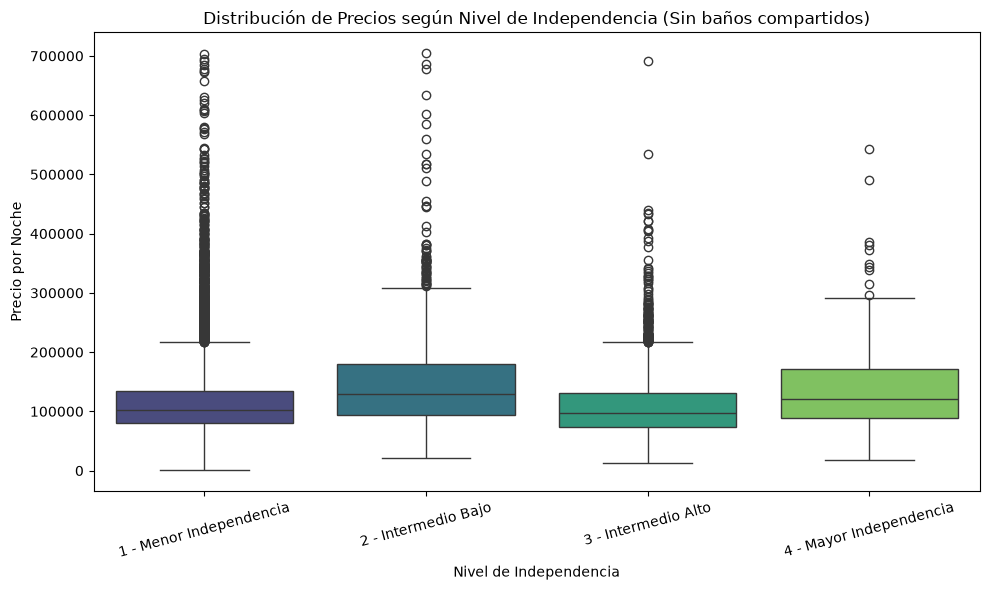


Mediana de precio por grupo:
nivel_independencia
1 - Menor Independencia    101652.625
2 - Intermedio Bajo        128971.410
3 - Intermedio Alto         97879.060
4 - Mayor Independencia    120616.500
Name: price_quote_price_per_night, dtype: float64


In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(10, 6))

# Creamos el boxplot asegurando el orden lógico de los grupos
sns.boxplot(
    data=df_final, 
    x='nivel_independencia', 
    y='price_quote_price_per_night', 
    order=[
        '1 - Menor Independencia', 
        '2 - Intermedio Bajo', 
        '3 - Intermedio Alto', 
        '4 - Mayor Independencia'
    ],
    palette='viridis'
)

# Añadimos títulos y ajustamos etiquetas
plt.title('Distribución de Precios según Nivel de Independencia (Sin baños compartidos)')
plt.xlabel('Nivel de Independencia')
plt.ylabel('Precio por Noche')
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

# Opcional: Calcular las medianas exactas para poner en la conclusión
print("\nMediana de precio por grupo:")
print(df_final.groupby('nivel_independencia')['price_quote_price_per_night'].median())